In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/fashion_mnist_subset.csv")

print("Dimensiones del dataset:", df.shape)
display(df.head())

Dimensiones del dataset: (25000, 785)


,pixel_0,pixel_1,pixel_2,pixel_3,pixel_4,pixel_5,pixel_6,pixel_7,pixel_8,pixel_9,...,pixel_775,pixel_776,pixel_777,pixel_778,pixel_779,pixel_780,pixel_781,pixel_782,pixel_783,label
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0039,0.0000,0.0196,0.0902,...,0.1647,0.0000,0.0000,0.0000,0.0000,0.0,0.0,0.0,0.0,3
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0000,0.0000,0.0000,0.0000,...,0.0000,0.0000,0.0000,0.0000,0.0000,0.0,0.0,0.0,0.0,4
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0000,0.0000,0.0000,0.0000,...,0.4235,0.2157,0.0000,0.0000,0.0000,0.0,0.0,0.0,0.0,0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0000,0.0627,0.2078,0.0000,...,0.0549,0.0000,0.1529,0.3843,0.0196,0.0,0.0,0.0,0.0,6
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0000,0.0000,0.0000,0.0000,...,0.0000,0.0000,0.0078,0.0000,0.0000,0.0,0.0,0.0,0.0,4


In [5]:
print(df.columns.tolist()[-10:])
print(df.dtypes.value_counts())
print(df.isnull().sum().sum())

['pixel_775', 'pixel_776', 'pixel_777', 'pixel_778', 'pixel_779', 'pixel_780', 'pixel_781', 'pixel_782', 'pixel_783', 'label']
float64    784
int64        1
Name: count, dtype: int64
0


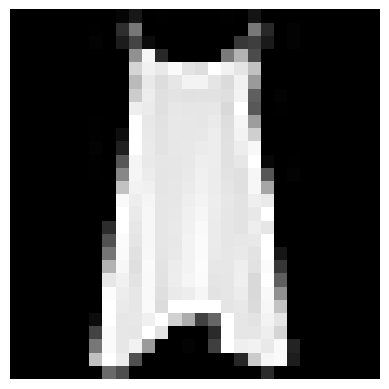

In [6]:
imagen = df.filter(regex=r"^pixel_").iloc[0].to_numpy().reshape(28, 28)

plt.imshow(imagen, cmap="gray")
plt.axis("off")
plt.show()

In [7]:
X = df.filter(regex=r"^pixel_").to_numpy()
y = df.drop(columns=df.filter(regex=r"^pixel_").columns).iloc[:, 0].to_numpy()

print("Imágenes:", X.shape)
print("Etiquetas:", y.shape)

Imágenes: (25000, 784)
Etiquetas: (25000,)


In [8]:
nombres_clases = {
    0: "Remera",
    1: "Pantalón",
    2: "Pulóver",
    3: "Vestido",
    4: "Abrigo",
    5: "Sandalia",
    6: "Camisa",
    7: "Zapatilla",
    8: "Bolso",
    9: "Bota"
}

In [9]:
def mostrar_imagenes(X, y, n=15, semilla=42):
    rng = np.random.default_rng(semilla)
    indices = rng.choice(len(X), size=n, replace=False)

    columnas = min(5, n)
    filas = int(np.ceil(n / columnas))

    fig, axes = plt.subplots(filas, columnas, figsize=(columnas * 2, filas * 2.5))
    axes = np.atleast_1d(axes).flatten()

    for ax, i in zip(axes, indices):
        imagen = X[i].reshape(28, 28)
        ax.imshow(imagen, cmap="gray", vmin=0, vmax=1)
        ax.set_title(f"{nombres_clases[y[i]]} ({y[i]})")
        ax.axis("off")

    for ax in axes[n:]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

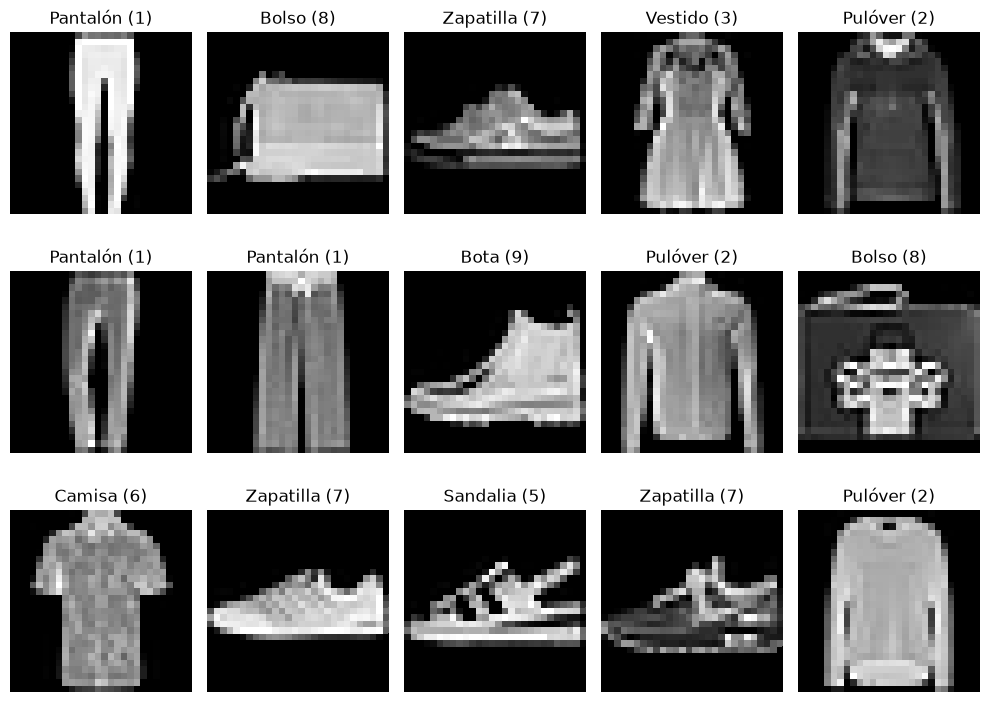

In [10]:
mostrar_imagenes(X, y, n=15)

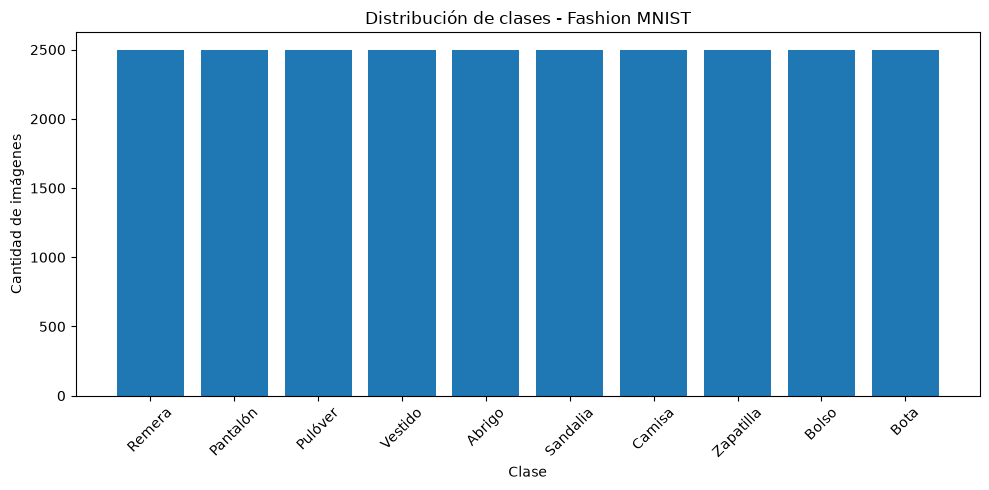

{np.int64(0): np.int64(2500), np.int64(1): np.int64(2500), np.int64(2): np.int64(2500), np.int64(3): np.int64(2500), np.int64(4): np.int64(2500), np.int64(5): np.int64(2500), np.int64(6): np.int64(2500), np.int64(7): np.int64(2500), np.int64(8): np.int64(2500), np.int64(9): np.int64(2500)}


In [11]:
clases, cantidades = np.unique(y, return_counts=True)

plt.figure(figsize=(10, 5))
plt.bar(clases, cantidades)

plt.xticks(
    clases,
    [nombres_clases[c] for c in clases],
    rotation=45
)

plt.xlabel("Clase")
plt.ylabel("Cantidad de imágenes")
plt.title("Distribución de clases - Fashion MNIST")
plt.tight_layout()
plt.show()

print(dict(zip(clases, cantidades)))

In [12]:
def mostrar_por_clase(X, y, clases_elegidas, n_por_clase=5, semilla=42):
    rng = np.random.default_rng(semilla)

    fig, axes = plt.subplots(
        len(clases_elegidas),
        n_por_clase,
        figsize=(n_por_clase * 2, len(clases_elegidas) * 2)
    )

    axes = np.array(axes).reshape(len(clases_elegidas), n_por_clase)

    for fila, clase in enumerate(clases_elegidas):
        indices_clase = np.where(y == clase)[0]
        seleccionados = rng.choice(indices_clase, n_por_clase, replace=False)

        for columna, indice in enumerate(seleccionados):
            ax = axes[fila, columna]
            ax.imshow(X[indice].reshape(28, 28), cmap="gray", vmin=0, vmax=1)
            ax.axis("off")

            if columna == 0:
                ax.set_ylabel(nombres_clases[clase], rotation=90, fontsize=11)

    plt.suptitle("Variabilidad de imágenes por clase - Fashion MNIST")
    plt.tight_layout()
    plt.show()

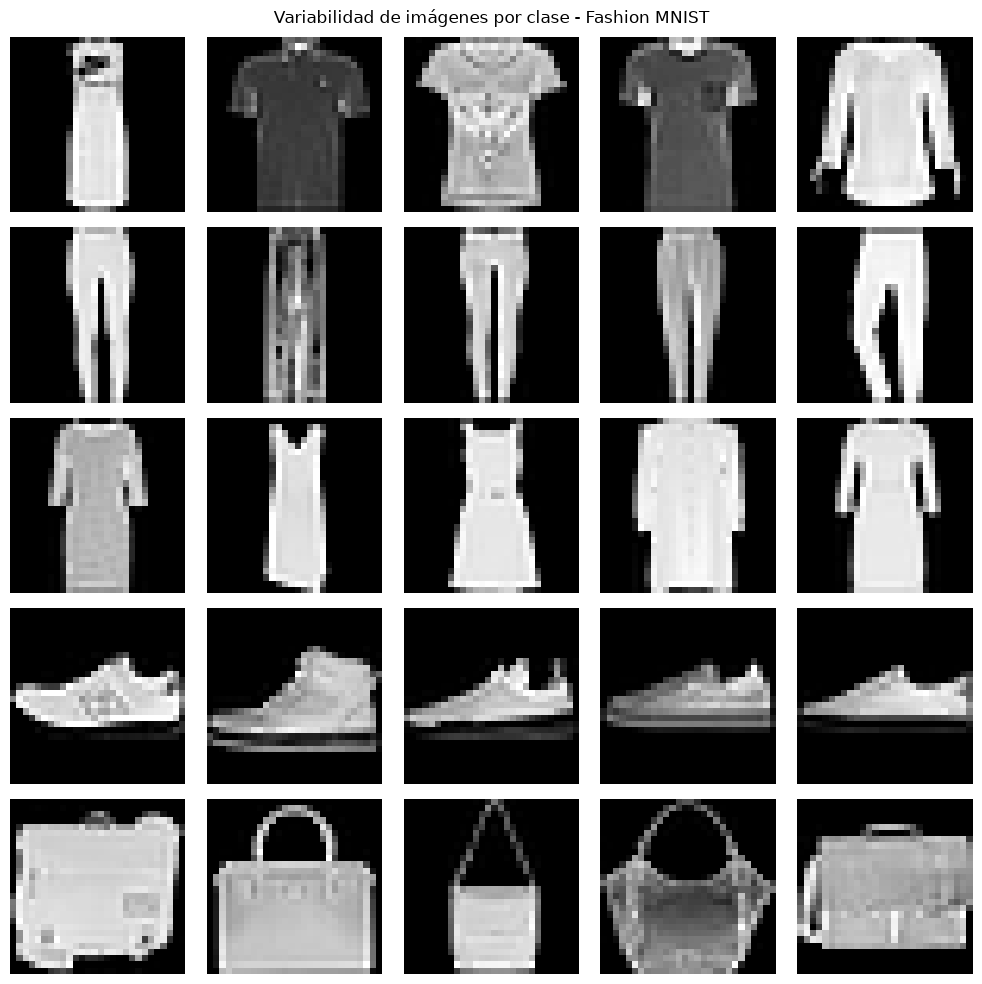

In [13]:
mostrar_por_clase(
    X, y,
    clases_elegidas=[0, 1, 3, 7, 8],
    n_por_clase=5
)

In [14]:
def split_estratificado(X, y, test_size=0.2, semilla=42):
    rng = np.random.default_rng(semilla)

    indices_train = []
    indices_test = []

    for clase in np.unique(y):
        indices = np.where(y == clase)[0]
        rng.shuffle(indices)

        n_test = int(len(indices) * test_size)

        indices_test.extend(indices[:n_test])
        indices_train.extend(indices[n_test:])

    indices_train = np.array(indices_train)
    indices_test = np.array(indices_test)

    rng.shuffle(indices_train)
    rng.shuffle(indices_test)

    return (
        X[indices_train],
        X[indices_test],
        y[indices_train],
        y[indices_test]
    )

In [15]:
X_train, X_test, y_train, y_test = split_estratificado(X, y)

print("Entrenamiento:", X_train.shape)
print("Evaluación:", X_test.shape)

print("\nDistribución de entrenamiento:")
print(np.unique(y_train, return_counts=True))

print("\nDistribución de evaluación:")
print(np.unique(y_test, return_counts=True))

Entrenamiento: (20000, 784)
Evaluación: (5000, 784)

Distribución de entrenamiento:
(array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9]), array([2000, 2000, 2000, 2000, 2000, 2000, 2000, 2000, 2000, 2000]))

Distribución de evaluación:
(array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9]), array([500, 500, 500, 500, 500, 500, 500, 500, 500, 500]))


## Ejercicio 2.a — Estandarización y PCA

In [39]:
def estandarizar(X_train, X_test):
    media = np.mean(X_train, axis=0)
    desvio = np.std(X_train, axis=0)

    # Evitamos dividir por cero en píxeles constantes
    desvio_seguro = np.where(desvio == 0, 1, desvio)

    X_train_std = (X_train - media) / desvio_seguro
    X_test_std = (X_test - media) / desvio_seguro

    return X_train_std, X_test_std, media, desvio_seguro

In [40]:
X_train_std, X_test_std, media, desvio = estandarizar(X_train, X_test)

print("Train estandarizado:", X_train_std.shape)
print("Test estandarizado:", X_test_std.shape)

print("Media máxima absoluta:", np.abs(X_train_std.mean(axis=0)).max())
print("Cantidad de píxeles constantes:", np.sum(np.std(X_train, axis=0) == 0))

Train estandarizado: (20000, 784)
Test estandarizado: (5000, 784)
Media máxima absoluta: 2.5236779332971083e-14
Cantidad de píxeles constantes: 0


In [41]:
def pca(X_train, X_test):
    # Matriz de covarianza
    cov = np.cov(X_train, rowvar=False)

    # Autovalores y autovectores
    autovalores, autovectores = np.linalg.eigh(cov)

    # Ordenamos de mayor a menor autovalor
    indices = np.argsort(autovalores)[::-1]

    autovalores = autovalores[indices]
    autovectores = autovectores[:, indices]

    # Proyectamos los datos
    X_train_pca = X_train @ autovectores
    X_test_pca = X_test @ autovectores

    return X_train_pca, X_test_pca, autovalores, autovectores

In [42]:
X_train_pca, X_test_pca, autovalores, autovectores = pca(
    X_train_std,
    X_test_std
)

print("Train PCA:", X_train_pca.shape)
print("Test PCA:", X_test_pca.shape)

print("Primeros 5 autovalores:", autovalores[:5])

Train PCA: (20000, 784)
Test PCA: (5000, 784)
Primeros 5 autovalores: [172.44859756 113.45440779  43.14137823  40.08024321  31.8053561 ]


In [43]:
# Varianza explicada por cada componente
varianza_explicada = autovalores / np.sum(autovalores)

# Varianza explicada acumulada
varianza_acumulada = np.cumsum(varianza_explicada)

# Cantidad mínima de componentes que explican el 90%
K = np.searchsorted(varianza_acumulada, 0.90) + 1

print("Componentes necesarias:", K)
print("Varianza explicada:", varianza_acumulada[K - 1])
print("Dimensionalidad original:", X_train.shape[1])

Componentes necesarias: 135
Varianza explicada: 0.9003688338555461
Dimensionalidad original: 784


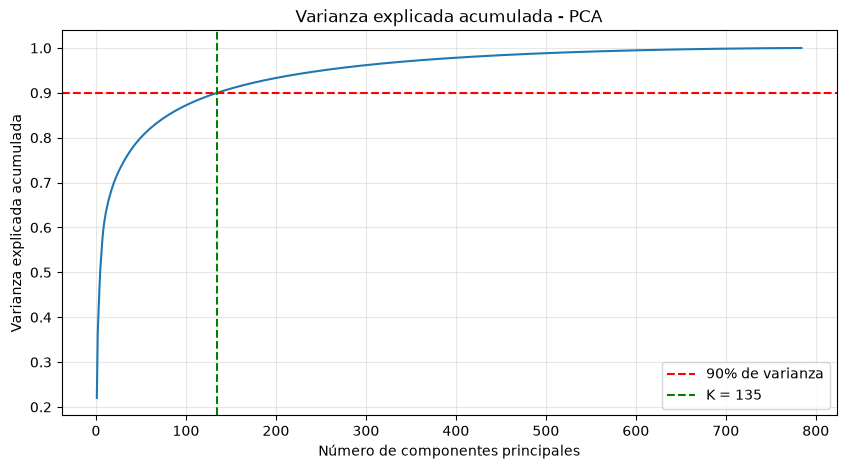

In [44]:
plt.figure(figsize=(10, 5))

plt.plot(
    np.arange(1, len(varianza_acumulada) + 1),
    varianza_acumulada
)

plt.axhline(0.90, color="red", linestyle="--",
            label="90% de varianza")

plt.axvline(K, color="green", linestyle="--",
            label=f"K = {K}")

plt.xlabel("Número de componentes principales")
plt.ylabel("Varianza explicada acumulada")
plt.title("Varianza explicada acumulada - PCA")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [45]:
X_train_reducido = X_train_pca[:, :K]
X_test_reducido = X_test_pca[:, :K]

print("Train reducido:", X_train_reducido.shape)
print("Test reducido:", X_test_reducido.shape)

Train reducido: (20000, 135)
Test reducido: (5000, 135)


In [46]:
def reconstruir_pca(X_reducido, autovectores, media, desvio):
    # Reconstrucción en el espacio estandarizado
    componentes = autovectores[:, :X_reducido.shape[1]]
    X_reconstruido_std = X_reducido @ componentes.T

    # Volvemos a la escala original
    X_reconstruido = X_reconstruido_std * desvio + media

    return np.clip(X_reconstruido, 0, 1)

In [47]:
rng = np.random.default_rng(42)
indices = rng.choice(len(X_test), size=10, replace=False)

imagenes_originales = X_test[indices]

imagenes_reconstruidas = reconstruir_pca(
    X_test_reducido[indices],
    autovectores,
    media,
    desvio
)

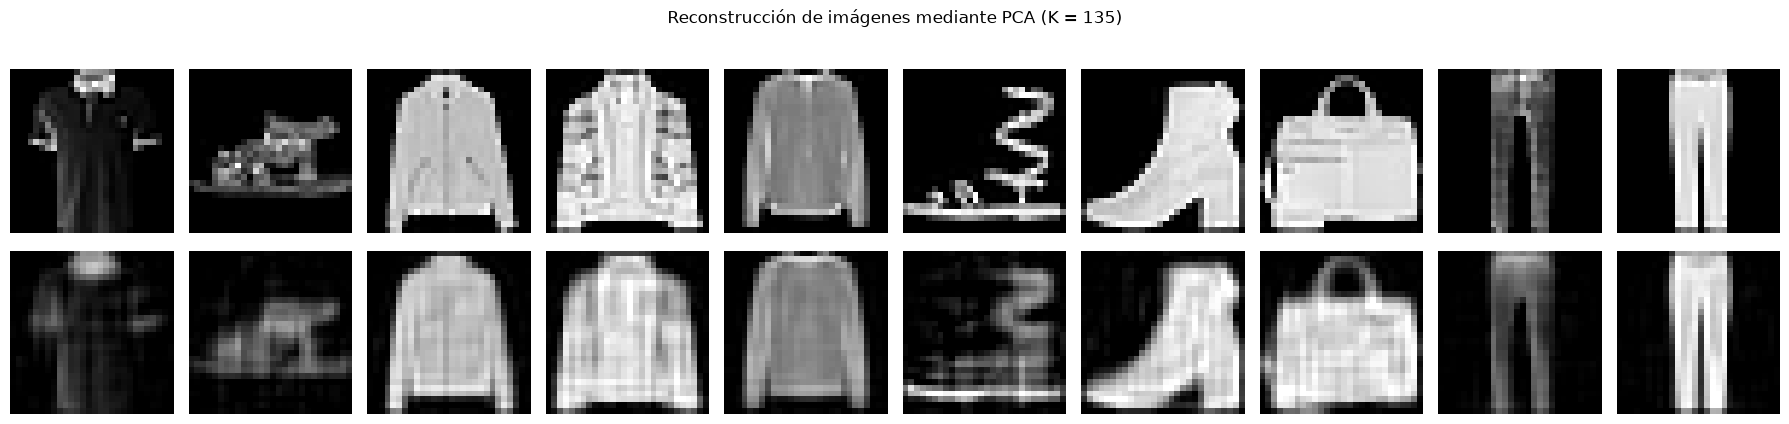

In [48]:
fig, axes = plt.subplots(2, 10, figsize=(18, 4.5))

for i in range(10):
    axes[0, i].imshow(
        imagenes_originales[i].reshape(28, 28),
        cmap="gray", vmin=0, vmax=1
    )
    axes[0, i].axis("off")

    axes[1, i].imshow(
        imagenes_reconstruidas[i].reshape(28, 28),
        cmap="gray", vmin=0, vmax=1
    )
    axes[1, i].axis("off")

axes[0, 0].set_ylabel("Original", fontsize=12)
axes[1, 0].set_ylabel("PCA", fontsize=12)

plt.suptitle(f"Reconstrucción de imágenes mediante PCA (K = {K})")
plt.tight_layout()
plt.show()

In [49]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

print("Versión de PyTorch:", torch.__version__)
print("MPS disponible:", torch.backends.mps.is_available())

Versión de PyTorch: 2.15.0
MPS disponible: True


In [50]:
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test, dtype=torch.float32)

train_dataset = TensorDataset(X_train_tensor, X_train_tensor)
test_dataset = TensorDataset(X_test_tensor, X_test_tensor)

train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=128, shuffle=False)

In [51]:
class Autoencoder(nn.Module):
    def __init__(self, latent_dim=135):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Linear(784, 512),
            nn.ReLU(),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Linear(256, latent_dim)
        )

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 256),
            nn.ReLU(),
            nn.Linear(256, 512),
            nn.ReLU(),
            nn.Linear(512, 784),
            nn.Sigmoid()
        )

    def forward(self, x):
        z = self.encoder(x)
        reconstruccion = self.decoder(z)
        return reconstruccion

In [52]:
torch.manual_seed(42)

device = torch.device(
    "mps" if torch.backends.mps.is_available() else "cpu"
)

modelo_ae = Autoencoder(latent_dim=K).to(device)

criterio = nn.MSELoss()
optimizador = torch.optim.Adam(modelo_ae.parameters(), lr=0.001)

print("Dispositivo:", device)
print("Dimensión latente:", K)
print("Parámetros entrenables:",
      sum(p.numel() for p in modelo_ae.parameters()))

Dispositivo: mps
Dimensión latente: 135
Parámetros entrenables: 1136535


In [53]:
def entrenar_ae(modelo, train_loader, test_loader, criterio, optimizador, epochs=30):
    historial_train = []
    historial_val = []

    for epoch in range(epochs):
        modelo.train()
        loss_train = 0

        for entradas, objetivos in train_loader:
            entradas = entradas.to(device)
            objetivos = objetivos.to(device)

            optimizador.zero_grad()

            reconstrucciones = modelo(entradas)
            loss = criterio(reconstrucciones, objetivos)

            loss.backward()
            optimizador.step()

            loss_train += loss.item() * entradas.size(0)

        loss_train /= len(train_loader.dataset)
        historial_train.append(loss_train)

        modelo.eval()
        loss_val = 0

        with torch.no_grad():
            for entradas, objetivos in test_loader:
                entradas = entradas.to(device)
                objetivos = objetivos.to(device)

                reconstrucciones = modelo(entradas)
                loss = criterio(reconstrucciones, objetivos)

                loss_val += loss.item() * entradas.size(0)

        loss_val /= len(test_loader.dataset)
        historial_val.append(loss_val)

        print(
            f"Epoch {epoch+1:02d}/{epochs} | "
            f"Train Loss: {loss_train:.6f} | "
            f"Val Loss: {loss_val:.6f}"
        )

    return historial_train, historial_val

In [54]:
historial_train, historial_val = entrenar_ae(
    modelo_ae,
    train_loader,
    test_loader,
    criterio,
    optimizador,
    epochs=30
)

Epoch 01/30 | Train Loss: 0.055553 | Val Loss: 0.034799
Epoch 02/30 | Train Loss: 0.027075 | Val Loss: 0.022945
Epoch 03/30 | Train Loss: 0.022116 | Val Loss: 0.020723
Epoch 04/30 | Train Loss: 0.020257 | Val Loss: 0.020106
Epoch 05/30 | Train Loss: 0.018726 | Val Loss: 0.017804
Epoch 06/30 | Train Loss: 0.017485 | Val Loss: 0.017318
Epoch 07/30 | Train Loss: 0.016697 | Val Loss: 0.016201
Epoch 08/30 | Train Loss: 0.015941 | Val Loss: 0.015591
Epoch 09/30 | Train Loss: 0.015264 | Val Loss: 0.015013
Epoch 10/30 | Train Loss: 0.014711 | Val Loss: 0.015184
Epoch 11/30 | Train Loss: 0.014223 | Val Loss: 0.014243
Epoch 12/30 | Train Loss: 0.013746 | Val Loss: 0.013914
Epoch 13/30 | Train Loss: 0.013318 | Val Loss: 0.013337
Epoch 14/30 | Train Loss: 0.012943 | Val Loss: 0.013182
Epoch 15/30 | Train Loss: 0.012661 | Val Loss: 0.012825
Epoch 16/30 | Train Loss: 0.012283 | Val Loss: 0.012427
Epoch 17/30 | Train Loss: 0.012042 | Val Loss: 0.012386
Epoch 18/30 | Train Loss: 0.011756 | Val Loss: 0

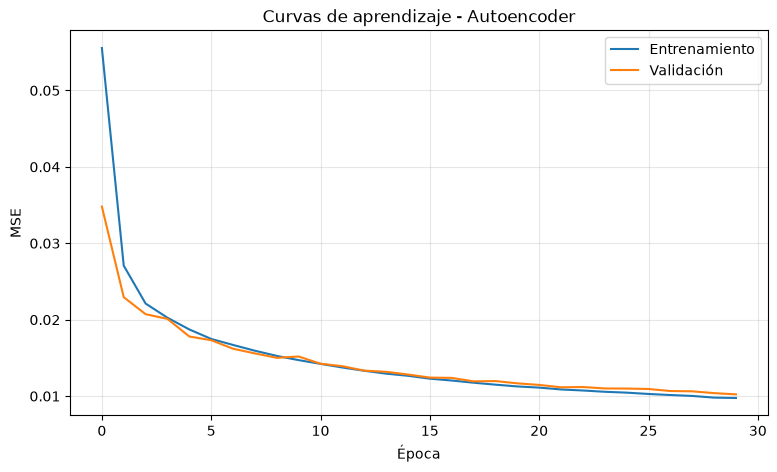

In [55]:
plt.figure(figsize=(9, 5))

plt.plot(historial_train, label="Entrenamiento")
plt.plot(historial_val, label="Validación")

plt.xlabel("Época")
plt.ylabel("MSE")
plt.title("Curvas de aprendizaje - Autoencoder")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [56]:
modelo_ae.eval()

with torch.no_grad():
    entradas = torch.tensor(
        imagenes_originales,
        dtype=torch.float32
    ).to(device)

    imagenes_ae = modelo_ae(entradas).cpu().numpy()

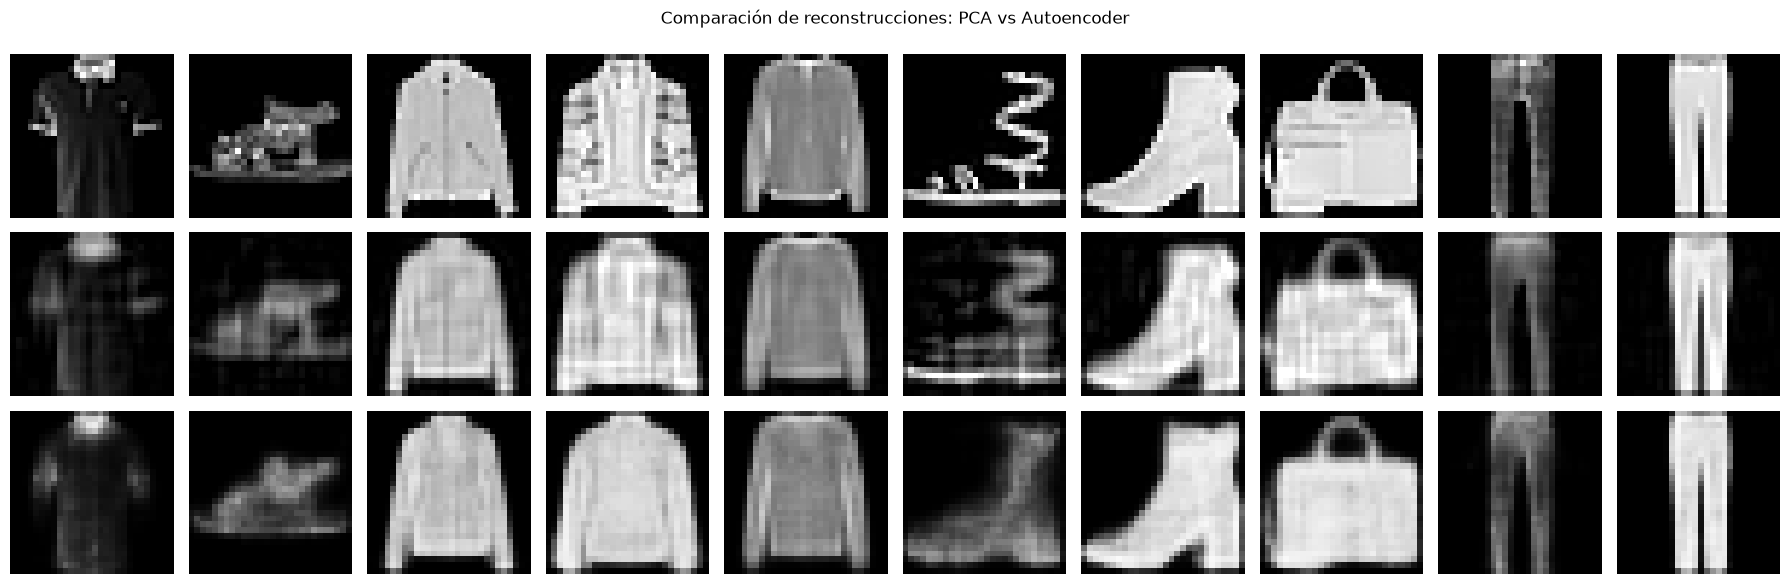

In [57]:
fig, axes = plt.subplots(3, 10, figsize=(18, 6))

for i in range(10):
    axes[0, i].imshow(
        imagenes_originales[i].reshape(28, 28),
        cmap="gray", vmin=0, vmax=1
    )

    axes[1, i].imshow(
        imagenes_reconstruidas[i].reshape(28, 28),
        cmap="gray", vmin=0, vmax=1
    )

    axes[2, i].imshow(
        imagenes_ae[i].reshape(28, 28),
        cmap="gray", vmin=0, vmax=1
    )

    for fila in range(3):
        axes[fila, i].axis("off")

axes[0, 0].set_ylabel("Original")
axes[1, 0].set_ylabel("PCA")
axes[2, 0].set_ylabel("Autoencoder")

plt.suptitle("Comparación de reconstrucciones: PCA vs Autoencoder")
plt.tight_layout()
plt.show()

In [58]:
mse_pca = np.mean(
    (imagenes_originales - imagenes_reconstruidas) ** 2
)

mse_ae = np.mean(
    (imagenes_originales - imagenes_ae) ** 2
)

print(f"MSE PCA: {mse_pca:.6f}")
print(f"MSE AE:  {mse_ae:.6f}")

MSE PCA: 0.009442
MSE AE:  0.013676


In [59]:
# Error de PCA en todo el conjunto de evaluación
X_pca_test_reconstruido = reconstruir_pca(
    X_test_reducido,
    autovectores,
    media,
    desvio
)

mse_pca_total = np.mean(
    (X_test - X_pca_test_reconstruido) ** 2
)

# Error del Autoencoder en todo el conjunto de evaluación
modelo_ae.eval()
reconstrucciones_ae = []

with torch.no_grad():
    for (entradas, _) in test_loader:
        entradas = entradas.to(device)
        reconstruccion = modelo_ae(entradas)
        reconstrucciones_ae.append(reconstruccion.cpu().numpy())

X_ae_test_reconstruido = np.concatenate(reconstrucciones_ae, axis=0)

mse_ae_total = np.mean(
    (X_test - X_ae_test_reconstruido) ** 2
)

print(f"MSE PCA (test): {mse_pca_total:.6f}")
print(f"MSE AE  (test): {mse_ae_total:.6f}")

MSE PCA (test): 0.007659
MSE AE  (test): 0.010231


In [60]:
def obtener_espacio_latente_ae(modelo, X, device, batch_size=128):
    modelo.eval()

    X_tensor = torch.tensor(X, dtype=torch.float32)
    loader = DataLoader(
        TensorDataset(X_tensor),
        batch_size=batch_size,
        shuffle=False
    )

    embeddings = []

    with torch.no_grad():
        for (entradas,) in loader:
            entradas = entradas.to(device)

            z = modelo.encoder(entradas)

            embeddings.append(z.cpu().numpy())

    return np.concatenate(embeddings, axis=0)

In [61]:
Z_train_ae = obtener_espacio_latente_ae(
    modelo_ae, X_train, device
)

Z_test_ae = obtener_espacio_latente_ae(
    modelo_ae, X_test, device
)

Z_train_pca = X_train_reducido
Z_test_pca = X_test_reducido

print("PCA Train:", Z_train_pca.shape)
print("PCA Test:", Z_test_pca.shape)

print("AE Train:", Z_train_ae.shape)
print("AE Test:", Z_test_ae.shape)

PCA Train: (20000, 135)
PCA Test: (5000, 135)
AE Train: (20000, 135)
AE Test: (5000, 135)


### 2.f - Variational Autoencoder (VAE)

In [ ]:
class VAE(nn.Module):
    def __init__(self, latent_dim=135):
        super().__init__()

        # Encoder
        self.encoder = nn.Sequential(
            nn.Linear(784, 512),
            nn.ReLU(),
            nn.Linear(512, 256),
            nn.ReLU()
        )

        # Parámetros de la distribución latente
        self.fc_mu = nn.Linear(256, latent_dim)
        self.fc_logvar = nn.Linear(256, latent_dim)

        # Decoder
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 256),
            nn.ReLU(),
            nn.Linear(256, 512),
            nn.ReLU(),
            nn.Linear(512, 784),
            nn.Sigmoid()
        )

    def encode(self, x):
        h = self.encoder(x)

        mu = self.fc_mu(h)
        logvar = self.fc_logvar(h)

        return mu, logvar

    def reparametrize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        epsilon = torch.randn_like(std)

        z = mu + epsilon * std

        return z

    def decode(self, z):
        return self.decoder(z)

    def forward(self, x):
        mu, logvar = self.encode(x)

        z = self.reparametrize(mu, logvar)

        reconstruccion = self.decode(z)

        return reconstruccion, mu, logvar

In [64]:
torch.manual_seed(42)

modelo_vae = VAE(latent_dim=K).to(device)

optimizador_vae = torch.optim.Adam(
    modelo_vae.parameters(),
    lr=0.001
)

print("Dispositivo:", device)
print("Dimensión latente:", K)

print(
    "Parámetros entrenables:",
    sum(p.numel() for p in modelo_vae.parameters()
        if p.requires_grad)
)

Dispositivo: mps
Dimensión latente: 135
Parámetros entrenables: 1171230


In [65]:
def perdida_vae(reconstruccion, x, mu, logvar, beta=1.0):

    # MSE promedio por píxel y por imagen
    loss_recon = nn.functional.mse_loss(
        reconstruccion, x, reduction="mean"
    )

    # KL promedio por dimensión latente y por imagen
    kl_por_imagen = -0.5 * torch.sum(
        1 + logvar - mu.pow(2) - logvar.exp(),
        dim=1
    )

    loss_kl = kl_por_imagen.mean() / mu.shape[1]

    # Pérdida total
    loss_total = loss_recon + beta * loss_kl

    return loss_total, loss_recon, loss_kl

In [66]:
entradas, _ = next(iter(train_loader))
entradas = entradas.to(device)

modelo_vae.eval()

with torch.no_grad():
    reconstruccion, mu, logvar = modelo_vae(entradas)

    loss_total, loss_recon, loss_kl = perdida_vae(
        reconstruccion,
        entradas,
        mu,
        logvar
    )

print(f"Loss total:          {loss_total.item():.6f}")
print(f"Loss reconstrucción: {loss_recon.item():.6f}")
print(f"Loss KL:             {loss_kl.item():.6f}")

print("Forma de mu:", mu.shape)
print("Forma de logvar:", logvar.shape)
print("Forma de reconstrucción:", reconstruccion.shape)

Loss total:          0.172142
Loss reconstrucción: 0.169331
Loss KL:             0.002811
Forma de mu: torch.Size([128, 135])
Forma de logvar: torch.Size([128, 135])
Forma de reconstrucción: torch.Size([128, 784])


In [67]:
def entrenar_vae(modelo, train_loader, test_loader, optimizador, epochs=30, beta=1.0):

    historial = {
        "train_total": [],
        "train_recon": [],
        "train_kl": [],
        "val_total": [],
        "val_recon": [],
        "val_kl": []
    }

    for epoch in range(epochs):

        # ENTRENAMIENTO
        modelo.train()

        train_total = 0
        train_recon = 0
        train_kl = 0

        for entradas, _ in train_loader:
            entradas = entradas.to(device)

            optimizador.zero_grad()

            reconstruccion, mu, logvar = modelo(entradas)

            loss, recon, kl = perdida_vae(
                reconstruccion, entradas, mu, logvar, beta
            )

            loss.backward()
            optimizador.step()

            n = entradas.size(0)

            train_total += loss.item() * n
            train_recon += recon.item() * n
            train_kl += kl.item() * n

        n_train = len(train_loader.dataset)

        historial["train_total"].append(train_total / n_train)
        historial["train_recon"].append(train_recon / n_train)
        historial["train_kl"].append(train_kl / n_train)

        # VALIDACIÓN
        modelo.eval()

        val_total = 0
        val_recon = 0
        val_kl = 0

        with torch.no_grad():

            for entradas, _ in test_loader:
                entradas = entradas.to(device)

                reconstruccion, mu, logvar = modelo(entradas)

                loss, recon, kl = perdida_vae(
                    reconstruccion, entradas, mu, logvar, beta
                )

                n = entradas.size(0)

                val_total += loss.item() * n
                val_recon += recon.item() * n
                val_kl += kl.item() * n

        n_val = len(test_loader.dataset)

        historial["val_total"].append(val_total / n_val)
        historial["val_recon"].append(val_recon / n_val)
        historial["val_kl"].append(val_kl / n_val)

        print(
            f"Época {epoch + 1:02d}/{epochs} | "
            f"Train: {historial['train_total'][-1]:.5f} | "
            f"Val: {historial['val_total'][-1]:.5f} | "
            f"Recon: {historial['val_recon'][-1]:.5f} | "
            f"KL: {historial['val_kl'][-1]:.5f}"
        )

    return historial

In [68]:
historial_vae = entrenar_vae(
    modelo_vae,
    train_loader,
    test_loader,
    optimizador_vae,
    epochs=30,
    beta=1.0
)

Época 01/30 | Train: 0.08795 | Val: 0.07793 | Recon: 0.07148 | KL: 0.00646
Época 02/30 | Train: 0.07558 | Val: 0.07193 | Recon: 0.06193 | KL: 0.01000
Época 03/30 | Train: 0.07223 | Val: 0.07031 | Recon: 0.05981 | KL: 0.01050
Época 04/30 | Train: 0.07198 | Val: 0.07062 | Recon: 0.05729 | KL: 0.01333
Época 05/30 | Train: 0.07155 | Val: 0.07041 | Recon: 0.05840 | KL: 0.01201
Época 06/30 | Train: 0.07050 | Val: 0.06924 | Recon: 0.05625 | KL: 0.01299
Época 07/30 | Train: 0.06776 | Val: 0.06539 | Recon: 0.05205 | KL: 0.01334
Época 08/30 | Train: 0.06569 | Val: 0.06526 | Recon: 0.05069 | KL: 0.01457
Época 09/30 | Train: 0.06509 | Val: 0.06396 | Recon: 0.04965 | KL: 0.01431
Época 10/30 | Train: 0.06485 | Val: 0.06395 | Recon: 0.04925 | KL: 0.01470
Época 11/30 | Train: 0.06448 | Val: 0.06313 | Recon: 0.04746 | KL: 0.01567
Época 12/30 | Train: 0.06449 | Val: 0.06341 | Recon: 0.04714 | KL: 0.01627
Época 13/30 | Train: 0.06410 | Val: 0.06322 | Recon: 0.04838 | KL: 0.01484
Época 14/30 | Train: 0.06

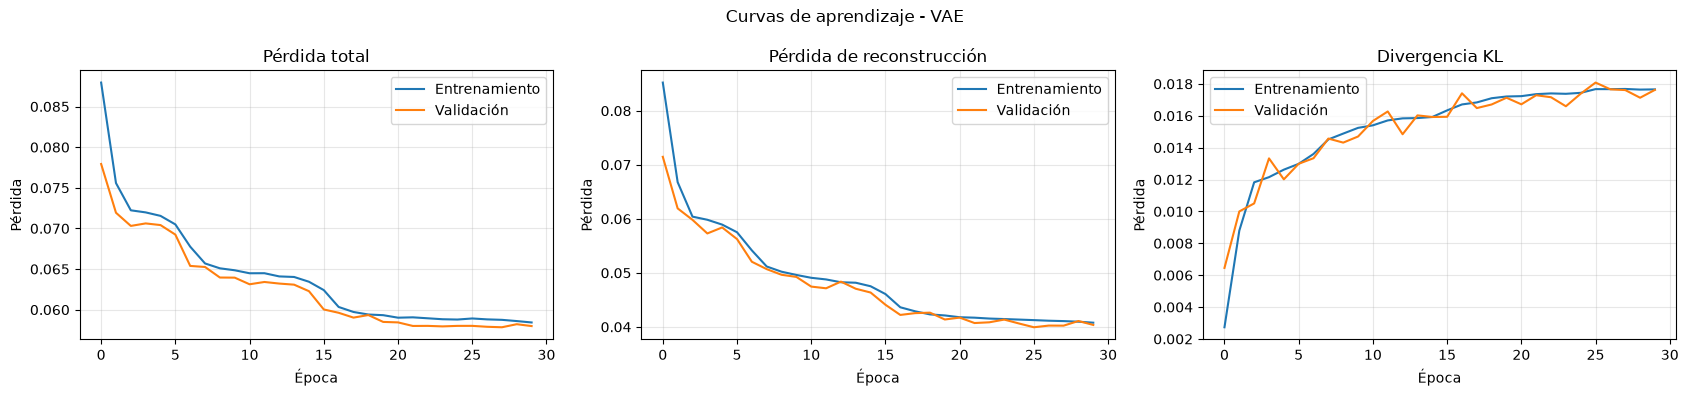

In [69]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))

metricas = [
    ("total", "Pérdida total"),
    ("recon", "Pérdida de reconstrucción"),
    ("kl", "Divergencia KL")
]

for ax, (clave, titulo) in zip(axes, metricas):

    ax.plot(
        historial_vae[f"train_{clave}"],
        label="Entrenamiento"
    )

    ax.plot(
        historial_vae[f"val_{clave}"],
        label="Validación"
    )

    ax.set_title(titulo)
    ax.set_xlabel("Época")
    ax.set_ylabel("Pérdida")
    ax.legend()
    ax.grid(alpha=0.3)

plt.suptitle("Curvas de aprendizaje - VAE")
plt.tight_layout()
plt.show()

In [70]:
modelo_vae.eval()

with torch.no_grad():
    entradas = torch.tensor(
        imagenes_originales,
        dtype=torch.float32
    ).to(device)

    mu, logvar = modelo_vae.encode(entradas)

    # Reconstruimos utilizando las medias
    imagenes_vae = modelo_vae.decode(mu).cpu().numpy()

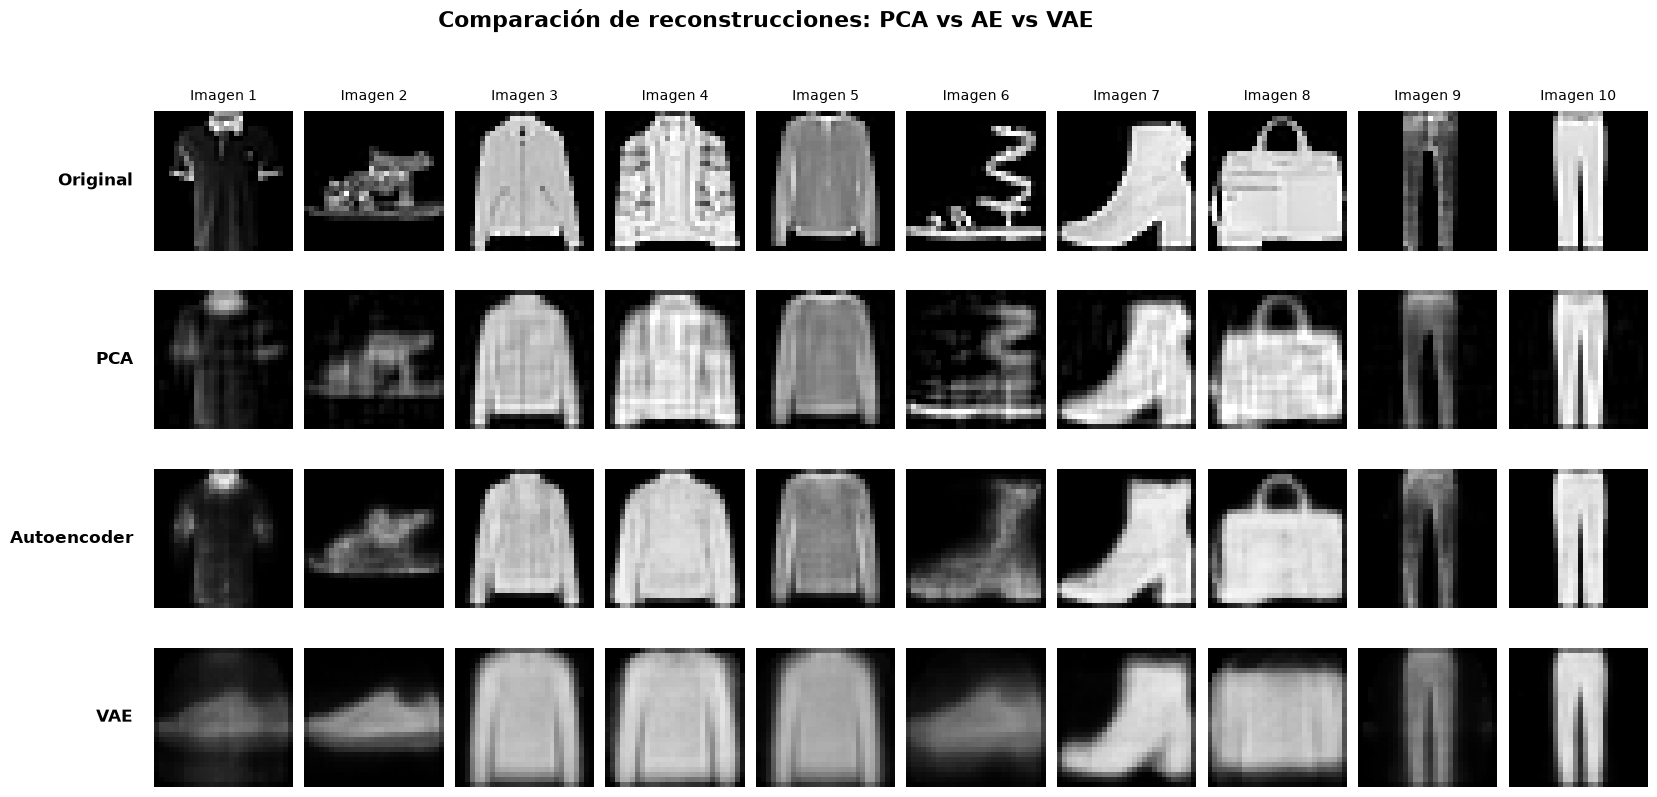

In [73]:
fig, axes = plt.subplots(4, 10, figsize=(18, 8))

conjuntos = [
    ("Original", imagenes_originales),
    ("PCA", imagenes_reconstruidas),
    ("Autoencoder", imagenes_ae),
    ("VAE", imagenes_vae)
]

for fila, (nombre, imagenes) in enumerate(conjuntos):
    for i in range(10):
        axes[fila, i].imshow(
            imagenes[i].reshape(28, 28),
            cmap="gray",
            vmin=0,
            vmax=1
        )
        axes[fila, i].axis("off")

        if fila == 0:
            axes[fila, i].set_title(
                f"Imagen {i+1}",
                fontsize=10,
                pad=8
            )

    # Etiqueta visible a la izquierda de cada fila
    axes[fila, 0].text(
        -0.15, 0.5,
        nombre,
        transform=axes[fila, 0].transAxes,
        fontsize=12,
        fontweight="bold",
        ha="right",
        va="center"
    )

plt.suptitle(
    "Comparación de reconstrucciones: PCA vs AE vs VAE",
    fontsize=16,
    fontweight="bold",
    y=1.02
)

plt.subplots_adjust(
    left=0.16,
    right=0.99,
    top=0.90,
    bottom=0.04,
    wspace=0.08,
    hspace=0.18
)

plt.show()

In [72]:
mse_vae = np.mean(
    (imagenes_originales - imagenes_vae) ** 2
)

print(f"MSE PCA: {mse_pca:.6f}")
print(f"MSE AE:  {mse_ae:.6f}")
print(f"MSE VAE: {mse_vae:.6f}")

MSE PCA: 0.009442
MSE AE:  0.013676
MSE VAE: 0.049050


In [74]:
torch.manual_seed(42)

modelo_vae_beta01 = VAE(latent_dim=K).to(device)

optimizador_vae_beta01 = torch.optim.Adam(
    modelo_vae_beta01.parameters(),
    lr=0.001
)

historial_vae_beta01 = entrenar_vae(
    modelo_vae_beta01,
    train_loader,
    test_loader,
    optimizador_vae_beta01,
    epochs=30,
    beta=0.1
)

Época 01/30 | Train: 0.06941 | Val: 0.05229 | Recon: 0.04627 | KL: 0.06019
Época 02/30 | Train: 0.04939 | Val: 0.04548 | Recon: 0.03883 | KL: 0.06651
Época 03/30 | Train: 0.04327 | Val: 0.03984 | Recon: 0.03219 | KL: 0.07650
Época 04/30 | Train: 0.03862 | Val: 0.03710 | Recon: 0.03048 | KL: 0.06629
Época 05/30 | Train: 0.03555 | Val: 0.03373 | Recon: 0.02721 | KL: 0.06522
Época 06/30 | Train: 0.03332 | Val: 0.03186 | Recon: 0.02549 | KL: 0.06371
Época 07/30 | Train: 0.03153 | Val: 0.03050 | Recon: 0.02457 | KL: 0.05926
Época 08/30 | Train: 0.03054 | Val: 0.02964 | Recon: 0.02368 | KL: 0.05961
Época 09/30 | Train: 0.02982 | Val: 0.02955 | Recon: 0.02351 | KL: 0.06039
Época 10/30 | Train: 0.02941 | Val: 0.02903 | Recon: 0.02282 | KL: 0.06212
Época 11/30 | Train: 0.02909 | Val: 0.02874 | Recon: 0.02244 | KL: 0.06297
Época 12/30 | Train: 0.02875 | Val: 0.02829 | Recon: 0.02217 | KL: 0.06122
Época 13/30 | Train: 0.02841 | Val: 0.02829 | Recon: 0.02213 | KL: 0.06164
Época 14/30 | Train: 0.02

In [75]:
modelo_vae_beta01.eval()

with torch.no_grad():
    entradas = torch.tensor(
        imagenes_originales,
        dtype=torch.float32
    ).to(device)

    mu_beta01, _ = modelo_vae_beta01.encode(entradas)

    imagenes_vae_beta01 = modelo_vae_beta01.decode(
        mu_beta01
    ).cpu().numpy()

In [76]:
mse_vae_beta01 = np.mean(
    (imagenes_originales - imagenes_vae_beta01) ** 2
)

print(f"MSE PCA:           {mse_pca:.6f}")
print(f"MSE AE:            {mse_ae:.6f}")
print(f"MSE VAE beta=1:    {mse_vae:.6f}")
print(f"MSE VAE beta=0.1:  {mse_vae_beta01:.6f}")

MSE PCA:           0.009442
MSE AE:            0.013676
MSE VAE beta=1:    0.049050
MSE VAE beta=0.1:  0.019571


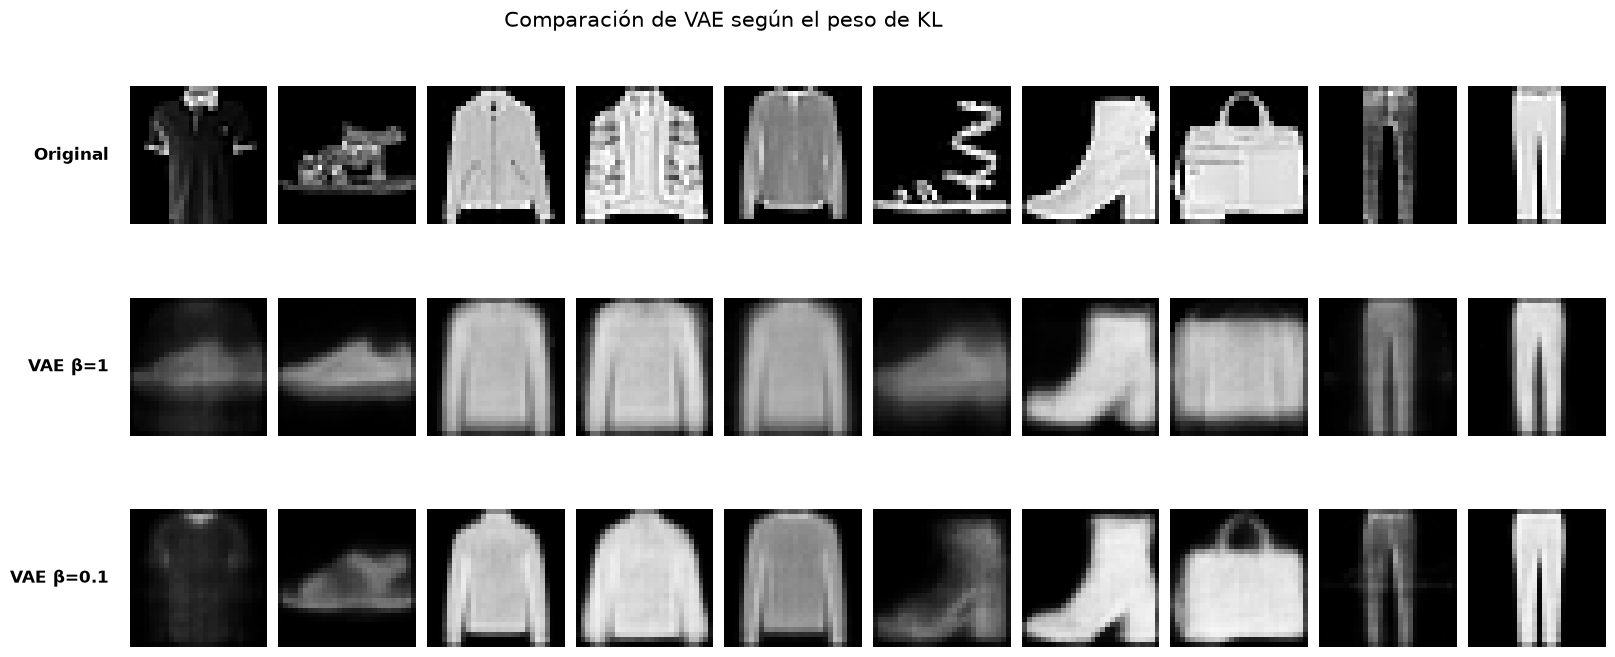

In [77]:
fig, axes = plt.subplots(3, 10, figsize=(18, 7))

conjuntos = [
    ("Original", imagenes_originales),
    ("VAE β=1", imagenes_vae),
    ("VAE β=0.1", imagenes_vae_beta01)
]

for fila, (nombre, imagenes) in enumerate(conjuntos):
    for i in range(10):
        axes[fila, i].imshow(
            imagenes[i].reshape(28, 28),
            cmap="gray",
            vmin=0,
            vmax=1
        )
        axes[fila, i].axis("off")

    axes[fila, 0].text(
        -0.15, 0.5, nombre,
        transform=axes[fila, 0].transAxes,
        fontsize=12,
        fontweight="bold",
        ha="right",
        va="center"
    )

plt.suptitle("Comparación de VAE según el peso de KL", fontsize=15)

plt.subplots_adjust(
    left=0.17,
    right=0.99,
    top=0.90,
    bottom=0.04,
    wspace=0.08,
    hspace=0.18
)

plt.show()

En el VAE con \(\beta=1\), varias prendas pierden su forma característica. Por ejemplo, las sandalias se parecen más a zapatos genéricos y algunas prendas superiores quedan muy difuminadas.

Con \(\beta=0.1\), las formas son mucho más reconocibles. Se recuperan mejor las siluetas de las prendas, los bolsos y el calzado, aunque siguen perdiéndose detalles finos.

Esto confirma que la regularización KL estaba limitando considerablemente la reconstrucción.

In [78]:
# Generamos los mismos vectores latentes para ambos modelos
torch.manual_seed(42)

n_imagenes = 10

z_aleatorio = torch.randn(
    n_imagenes, K,
    device=device
)

modelo_vae.eval()
modelo_vae_beta01.eval()

with torch.no_grad():
    generadas_beta1 = modelo_vae.decode(
        z_aleatorio
    ).cpu().numpy()

    generadas_beta01 = modelo_vae_beta01.decode(
        z_aleatorio
    ).cpu().numpy()

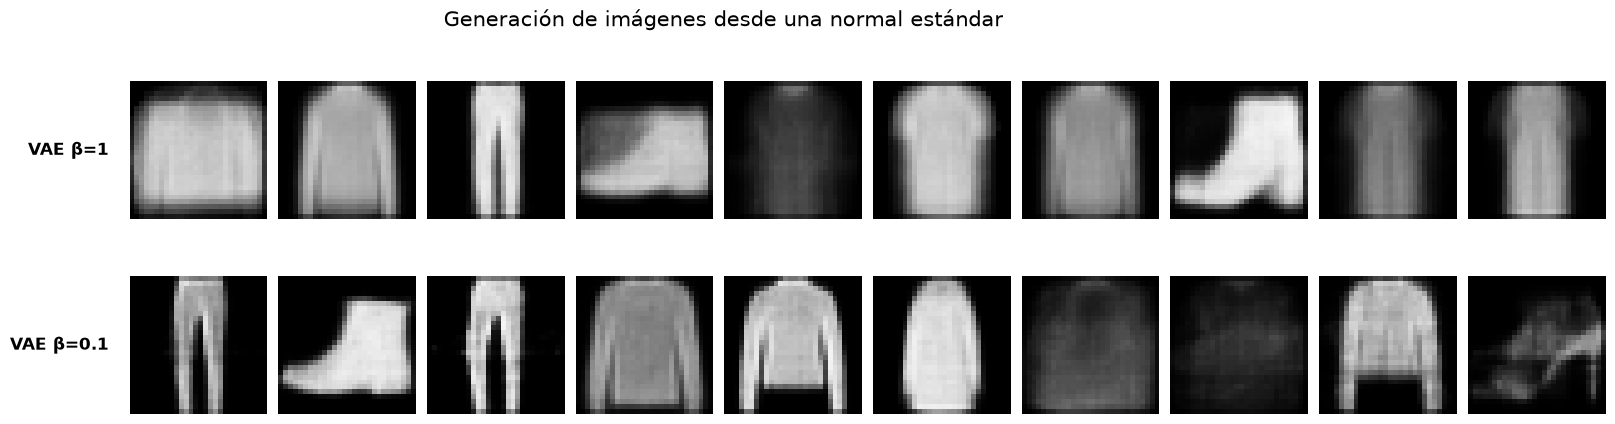

In [79]:
fig, axes = plt.subplots(2, 10, figsize=(18, 4.5))

conjuntos = [
    ("VAE β=1", generadas_beta1),
    ("VAE β=0.1", generadas_beta01)
]

for fila, (nombre, imagenes) in enumerate(conjuntos):
    for i in range(n_imagenes):
        axes[fila, i].imshow(
            imagenes[i].reshape(28, 28),
            cmap="gray",
            vmin=0,
            vmax=1
        )
        axes[fila, i].axis("off")

    axes[fila, 0].text(
        -0.15, 0.5,
        nombre,
        transform=axes[fila, 0].transAxes,
        fontsize=12,
        fontweight="bold",
        ha="right",
        va="center"
    )

plt.suptitle(
    "Generación de imágenes desde una normal estándar",
    fontsize=15
)

plt.subplots_adjust(
    left=0.17,
    right=0.99,
    top=0.85,
    bottom=0.05,
    wspace=0.08,
    hspace=0.18
)

plt.show()

In [80]:
# Seleccionamos 4 zapatillas del conjunto de validación
clase_elegida = 7
n_imagenes = 4

rng = np.random.default_rng(42)

indices_clase = np.where(y_test == clase_elegida)[0]

indices_elegidos = rng.choice(
    indices_clase,
    size=n_imagenes,
    replace=False
)

imagenes_clase = X_test[indices_elegidos]

print("Dimensiones:", imagenes_clase.shape)
print("Etiquetas:", y_test[indices_elegidos])

Dimensiones: (4, 784)
Etiquetas: [7 7 7 7]


In [81]:
modelo_vae_beta01.eval()

with torch.no_grad():

    entradas = torch.tensor(
        imagenes_clase,
        dtype=torch.float32
    ).to(device)

    # Extraemos las medias latentes
    mu, logvar = modelo_vae_beta01.encode(entradas)

    # Promediamos los 4 embeddings
    embedding_promedio = mu.mean(dim=0, keepdim=True)

    # Reconstruimos desde el embedding promedio
    imagen_promedio_latente = modelo_vae_beta01.decode(
        embedding_promedio
    ).cpu().numpy()

print("Embeddings originales:", mu.shape)
print("Embedding promedio:", embedding_promedio.shape)
print("Imagen generada:", imagen_promedio_latente.shape)

Embeddings originales: torch.Size([4, 135])
Embedding promedio: torch.Size([1, 135])
Imagen generada: (1, 784)


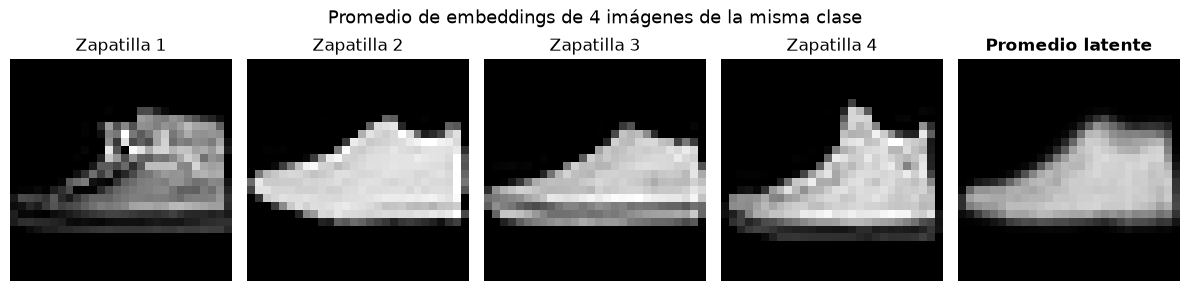

In [82]:
fig, axes = plt.subplots(1, 5, figsize=(12, 3))

for i in range(4):
    axes[i].imshow(
        imagenes_clase[i].reshape(28, 28),
        cmap="gray",
        vmin=0,
        vmax=1
    )
    axes[i].set_title(f"Zapatilla {i+1}")
    axes[i].axis("off")

axes[4].imshow(
    imagen_promedio_latente[0].reshape(28, 28),
    cmap="gray",
    vmin=0,
    vmax=1
)

axes[4].set_title("Promedio latente", fontweight="bold")
axes[4].axis("off")

plt.suptitle(
    "Promedio de embeddings de 4 imágenes de la misma clase",
    fontsize=13
)

plt.tight_layout()
plt.show()

Se seleccionaron cuatro imágenes de la clase zapatilla del conjunto de validación y se calcularon sus representaciones latentes mediante el encoder del VAE con β = 0,1. Posteriormente, se promediaron las medias latentes y se utilizó el decoder para generar una imagen. El resultado conservó la silueta general de una zapatilla, aunque presentó una pérdida de detalles y texturas. Esto sugiere que el espacio latente permite obtener representaciones intermedias coherentes para las muestras analizadas.

In [83]:
modelo_vae_beta01.eval()

embeddings_vae = []

with torch.no_grad():
    for entradas, _ in test_loader:
        entradas = entradas.to(device)

        mu, logvar = modelo_vae_beta01.encode(entradas)

        embeddings_vae.append(mu.cpu().numpy())

Z_test_vae = np.concatenate(embeddings_vae, axis=0)

print("AE:", Z_test_ae.shape)
print("VAE:", Z_test_vae.shape)

AE: (5000, 135)
VAE: (5000, 135)


In [84]:
def proyectar_2d(Z):
    Z_centrado = Z - Z.mean(axis=0)

    U, S, Vt = np.linalg.svd(
        Z_centrado,
        full_matrices=False
    )

    return Z_centrado @ Vt[:2].T


Z_ae_2d = proyectar_2d(Z_test_ae)
Z_vae_2d = proyectar_2d(Z_test_vae)

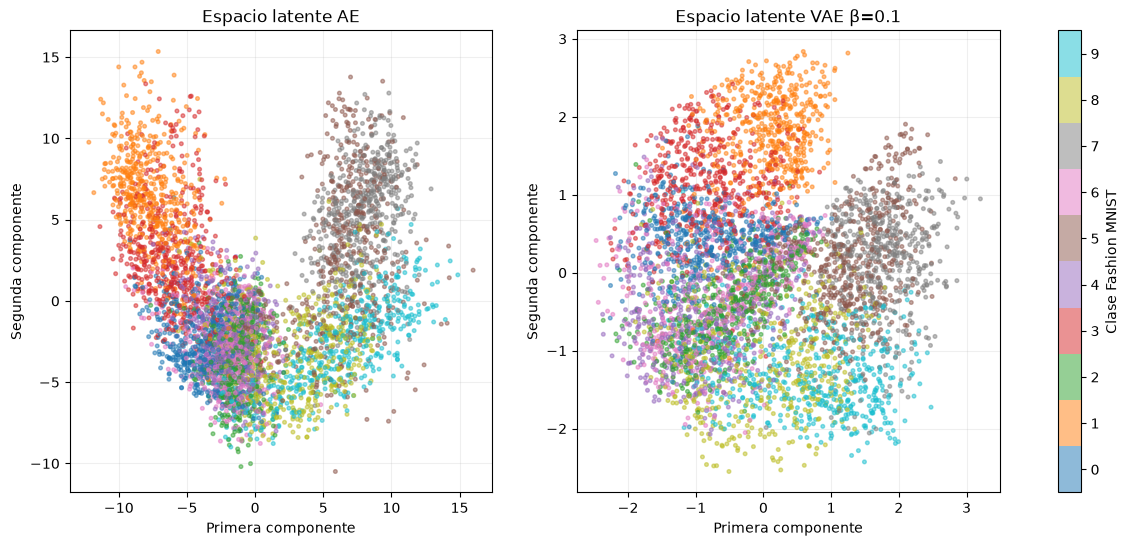

In [85]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

representaciones = [
    ("Espacio latente AE", Z_ae_2d),
    ("Espacio latente VAE β=0.1", Z_vae_2d)
]

for ax, (titulo, Z_2d) in zip(axes, representaciones):

    scatter = ax.scatter(
        Z_2d[:, 0],
        Z_2d[:, 1],
        c=y_test,
        cmap="tab10",
        s=7,
        alpha=0.5,
        vmin=-0.5,
        vmax=9.5
    )

    ax.set_title(titulo)
    ax.set_xlabel("Primera componente")
    ax.set_ylabel("Segunda componente")
    ax.grid(alpha=0.2)

cbar = fig.colorbar(scatter, ax=axes, ticks=range(10))
cbar.set_label("Clase Fashion MNIST")

plt.show()

Se visualizaron las representaciones latentes del Autoencoder y del VAE mediante una proyección a dos componentes principales. En ambos casos se identificaron regiones relativamente diferenciadas para determinadas clases, como pantalones y bolsos, mientras que otras clases presentaron una superposición considerable. Esto sugiere que los modelos aprendieron características visuales relevantes sin utilizar las etiquetas durante el entrenamiento. No obstante, la proyección bidimensional implica pérdida de información, por lo que la calidad de los agrupamientos deberá evaluarse mediante métodos específicos de clustering.

## 3. Clustering

### 3.a. Implementación de K-Means

In [86]:
# Seleccionamos una muestra estratificada de 3000 imágenes
rng = np.random.default_rng(42)

indices_muestra = []

for clase in np.unique(y_train):

    indices_clase = np.where(y_train == clase)[0]

    seleccionados = rng.choice(
        indices_clase,
        size=300,
        replace=False
    )

    indices_muestra.extend(seleccionados)

indices_muestra = np.array(indices_muestra)
rng.shuffle(indices_muestra)

# Trabajamos con el espacio latente de PCA
X_cluster = Z_train_pca[indices_muestra]
y_cluster = y_train[indices_muestra]

print("Dimensiones:", X_cluster.shape)
print("Distribución de clases:")
print(np.unique(y_cluster, return_counts=True))

Dimensiones: (3000, 135)
Distribución de clases:
(array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9]), array([300, 300, 300, 300, 300, 300, 300, 300, 300, 300]))


In [87]:
def kmeans_propio(X, k, max_iter=100, tol=1e-4, semilla=42):

    rng = np.random.default_rng(semilla)

    # 1. Inicialización aleatoria de centroides
    indices = rng.choice(len(X), size=k, replace=False)
    centroides = X[indices].copy()

    for iteracion in range(max_iter):

        # 2. Distancia cuadrática a cada centroide
        distancias = np.sum(
            (X[:, np.newaxis, :] - centroides[np.newaxis, :, :]) ** 2,
            axis=2
        )

        # 3. Asignar cada punto al centroide más cercano
        etiquetas = np.argmin(distancias, axis=1)

        # 4. Actualizar centroides
        nuevos_centroides = centroides.copy()

        for j in range(k):
            puntos_cluster = X[etiquetas == j]

            if len(puntos_cluster) > 0:
                nuevos_centroides[j] = puntos_cluster.mean(axis=0)
            else:
                # Reinicializar un cluster vacío
                nuevos_centroides[j] = X[rng.integers(len(X))]

        # 5. Verificar convergencia
        desplazamiento = np.linalg.norm(
            nuevos_centroides - centroides,
            axis=1
        ).max()

        centroides = nuevos_centroides

        if desplazamiento < tol:
            break

    # Asignación final con los centroides definitivos
    distancias_finales = np.sum(
        (X[:, np.newaxis, :] - centroides[np.newaxis, :, :]) ** 2,
        axis=2
    )

    etiquetas = np.argmin(distancias_finales, axis=1)

    # Inercia: suma de distancias cuadráticas al centroide asignado
    inercia = np.sum(
        distancias_finales[np.arange(len(X)), etiquetas]
    )

    return etiquetas, centroides, inercia, iteracion + 1

In [88]:
etiquetas_kmeans, centroides_kmeans, inercia_kmeans, iteraciones = (
    kmeans_propio(X_cluster, k=10)
)

print("Cantidad de clusters:", len(np.unique(etiquetas_kmeans)))
print("Centroides:", centroides_kmeans.shape)
print("Inercia:", round(inercia_kmeans, 2))
print("Iteraciones:", iteraciones)

print(
    "Cantidad de imágenes por cluster:",
    np.bincount(etiquetas_kmeans, minlength=10)
)

Cantidad de clusters: 10
Centroides: (10, 135)
Inercia: 1074730.84
Iteraciones: 31
Cantidad de imágenes por cluster: [218 325 126 513 344 497 296 120 207 354]


In [90]:
valores_k = range(5, 16)

inercias = []
iteraciones_k = []

for k in valores_k:

    etiquetas, centroides, inercia, n_iter = kmeans_propio(
        X_cluster,
        k=k,
        max_iter=100,
        semilla=42
    )

    inercias.append(inercia)
    iteraciones_k.append(n_iter)

    print(
        f"K={k:2d} | "
        f"Inercia={inercia:.2f} | "
        f"Iteraciones={n_iter}"
    )

K= 5 | Inercia=1321359.12 | Iteraciones=16
K= 6 | Inercia=1245186.42 | Iteraciones=94
K= 7 | Inercia=1173211.92 | Iteraciones=29
K= 8 | Inercia=1137776.67 | Iteraciones=26
K= 9 | Inercia=1108259.30 | Iteraciones=59
K=10 | Inercia=1074730.84 | Iteraciones=31
K=11 | Inercia=1062406.94 | Iteraciones=42
K=12 | Inercia=1006608.54 | Iteraciones=41
K=13 | Inercia=988433.07 | Iteraciones=40
K=14 | Inercia=974773.22 | Iteraciones=37
K=15 | Inercia=967120.41 | Iteraciones=37


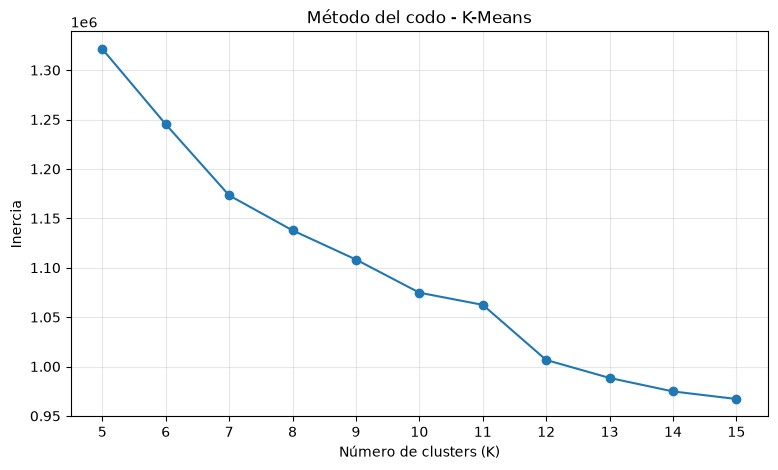

In [91]:
plt.figure(figsize=(9, 5))

plt.plot(
    list(valores_k),
    inercias,
    marker="o"
)

plt.xlabel("Número de clusters (K)")
plt.ylabel("Inercia")
plt.title("Método del codo - K-Means")
plt.xticks(list(valores_k))
plt.grid(alpha=0.3)

plt.show()

In [93]:
def silhouette_propio(X, etiquetas):
    n = len(X)

    # Matriz de distancias euclidianas
    distancias = np.sqrt(
        np.maximum(
            np.sum(X**2, axis=1)[:, None]
            + np.sum(X**2, axis=1)[None, :]
            - 2 * X @ X.T,
            0
        )
    )

    clases = np.unique(etiquetas)
    valores = np.zeros(n)

    for i in range(n):

        mismo_cluster = etiquetas == etiquetas[i]
        n_mismo = np.sum(mismo_cluster)

        if n_mismo <= 1:
            valores[i] = 0
            continue

        # Distancia promedio dentro de su cluster
        a = np.sum(distancias[i, mismo_cluster]) / (n_mismo - 1)

        # Distancia promedio al cluster vecino más cercano
        b = np.inf

        for cluster in clases:
            if cluster == etiquetas[i]:
                continue

            otro_cluster = etiquetas == cluster

            if np.any(otro_cluster):
                distancia_media = np.mean(
                    distancias[i, otro_cluster]
                )
                b = min(b, distancia_media)

        valores[i] = (b - a) / max(a, b)

    return np.mean(valores)

In [94]:
rng = np.random.default_rng(42)

indices_silhouette = rng.choice(
    len(X_cluster),
    size=1000,
    replace=False
)

X_silhouette = X_cluster[indices_silhouette]

valores_k = range(5, 16)
silhouettes = []

for k in valores_k:

    # Ajustamos K-Means sobre los 3000 puntos
    etiquetas, _, _, _ = kmeans_propio(
        X_cluster,
        k=k,
        semilla=42
    )

    # Asignaciones correspondientes a la muestra fija
    etiquetas_muestra = etiquetas[indices_silhouette]

    score = silhouette_propio(
        X_silhouette,
        etiquetas_muestra
    )

    silhouettes.append(score)

    print(f"K={k:2d} | Silhouette={score:.4f}")

K= 5 | Silhouette=0.1770
K= 6 | Silhouette=0.1520
K= 7 | Silhouette=0.1650
K= 8 | Silhouette=0.1664
K= 9 | Silhouette=0.1545
K=10 | Silhouette=0.1432
K=11 | Silhouette=0.1561
K=12 | Silhouette=0.1531
K=13 | Silhouette=0.1454
K=14 | Silhouette=0.1390
K=15 | Silhouette=0.1173


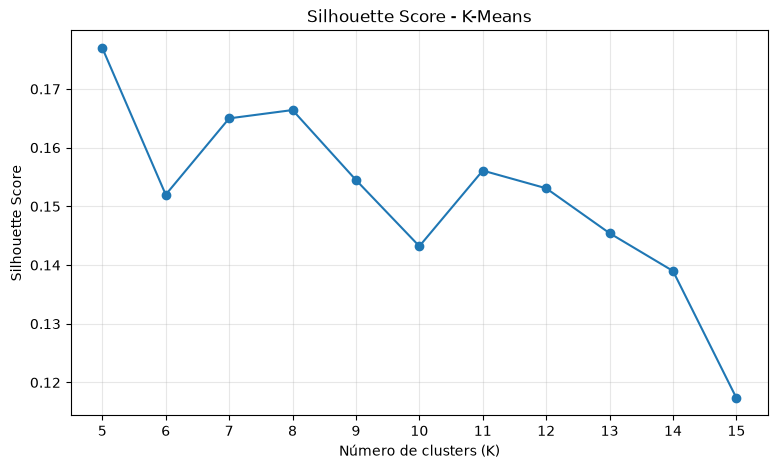

In [95]:
plt.figure(figsize=(9, 5))

plt.plot(
    list(valores_k),
    silhouettes,
    marker="o"
)

plt.xlabel("Número de clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score - K-Means")
plt.xticks(list(valores_k))
plt.grid(alpha=0.3)

plt.show()

Se evaluó K-Means para valores de K entre 5 y 15 utilizando representaciones PCA de 135 dimensiones. La inercia disminuyó al aumentar la cantidad de clusters, aunque no se identificó un codo único claramente definido. El mayor coeficiente Silhouette se obtuvo para K = 5, con un valor de 0,1770. Este resultado indica una separación relativamente débil entre los agrupamientos, posiblemente relacionada con las similitudes visuales entre determinadas clases de prendas. Por este motivo, se seleccionó K = 5 como referencia para el análisis posterior.

### 3.b. Gaussian Mixture Models (GMM)

In [102]:
def gmm_propio(X, k, max_iter=100, tol=1e-4, semilla=42, reg=1e-6):

    n, d = X.shape

    # 1. INICIALIZACIÓN CON K-MEANS
    etiquetas_ini, centroides_ini, _, _ = kmeans_propio(
        X,
        k=k,
        semilla=semilla
    )

    medias = centroides_ini.copy()

    varianzas = np.zeros((k, d))
    pesos = np.zeros(k)

    for j in range(k):
        puntos = X[etiquetas_ini == j]

        if len(puntos) > 0:
            pesos[j] = len(puntos) / n
            varianzas[j] = np.var(puntos, axis=0) + reg
        else:
            pesos[j] = 1 / n
            varianzas[j] = np.var(X, axis=0) + reg

    pesos = pesos / pesos.sum()

    historial_loglik = []

    # 2. ALGORITMO EXPECTATION-MAXIMIZATION
    for iteracion in range(max_iter):

        # E-STEP: calcular log-probabilidades
        log_prob = np.zeros((n, k))

        for j in range(k):

            diferencias = X - medias[j]

            log_det = np.sum(np.log(varianzas[j]))

            mahalanobis = np.sum(
                diferencias**2 / varianzas[j],
                axis=1
            )

            log_prob[:, j] = (
                np.log(pesos[j] + 1e-12)
                - 0.5 * (
                    d * np.log(2 * np.pi)
                    + log_det
                    + mahalanobis
                )
            )

        # Normalización estable
        max_log = np.max(log_prob, axis=1, keepdims=True)

        exp_log = np.exp(log_prob - max_log)

        suma_exp = np.sum(exp_log, axis=1, keepdims=True)

        responsabilidades = exp_log / suma_exp

        # Log-likelihood
        log_likelihood = np.sum(
            max_log[:, 0] + np.log(suma_exp[:, 0])
        )

        historial_loglik.append(log_likelihood)

        # M-STEP: actualizar parámetros
        Nk = responsabilidades.sum(axis=0) + 1e-12

        pesos = Nk / n

        medias = (
            responsabilidades.T @ X
        ) / Nk[:, None]

        for j in range(k):

            diferencias = X - medias[j]

            varianzas[j] = (
                responsabilidades[:, j][:, None]
                * diferencias**2
            ).sum(axis=0) / Nk[j] + reg

        # Criterio de convergencia
        if len(historial_loglik) > 1:

            mejora = (
                historial_loglik[-1]
                - historial_loglik[-2]
            )

            if abs(mejora) < tol:
                break

    # 3. E-STEP FINAL CON LOS PARÁMETROS DEFINITIVOS
    log_prob_final = np.zeros((n, k))

    for j in range(k):

        diferencias = X - medias[j]

        log_det = np.sum(np.log(varianzas[j]))

        mahalanobis = np.sum(
            diferencias**2 / varianzas[j],
            axis=1
        )

        log_prob_final[:, j] = (
            np.log(pesos[j] + 1e-12)
            - 0.5 * (
                d * np.log(2 * np.pi)
                + log_det
                + mahalanobis
            )
        )

    # Asignación final según la mayor probabilidad posterior
    etiquetas = np.argmax(log_prob_final, axis=1)

    # Log-likelihood final con parámetros actualizados
    max_log_final = np.max(
        log_prob_final,
        axis=1,
        keepdims=True
    )

    loglik_final = np.sum(
        max_log_final[:, 0]
        + np.log(
            np.sum(
                np.exp(log_prob_final - max_log_final),
                axis=1
            )
        )
    )

    historial_loglik.append(loglik_final)

    return (
        etiquetas,
        medias,
        varianzas,
        pesos,
        historial_loglik
    )

In [ ]:
etiquetas_gmm, medias_gmm, varianzas_gmm, pesos_gmm, loglik_gmm = (
    gmm_propio(X_cluster, k=5)
)

print("Cantidad de clusters:", len(np.unique(etiquetas_gmm)))
print("Medias:", medias_gmm.shape)
print("Varianzas:", varianzas_gmm.shape)
print("Pesos:", np.round(pesos_gmm, 4))
print("Iteraciones EM:", len(loglik_gmm) - 1)
print("Log-likelihood final:", round(loglik_gmm[-1], 2))
print("Última mejora:", round(loglik_gmm[-1] - loglik_gmm[-2], 6))
print("Imágenes por cluster:", np.bincount(etiquetas_gmm, minlength=5))

Cantidad de clusters: 5
Medias: (5, 135)
Varianzas: (5, 135)
Pesos: [0.1906 0.1358 0.2652 0.3838 0.0246]
Iteraciones EM: 100
Log-likelihood final: -614881.87
Última mejora: 0.00026
Imágenes por cluster: [ 572  410  797 1147   74]


In [105]:
valores_k_gmm = range(5, 16)

loglik_gmm_k = []
silhouettes_gmm = []
modelos_gmm = {}

for k in valores_k_gmm:

    etiquetas, medias, varianzas, pesos, historial = gmm_propio(
        X_cluster,
        k=k,
        max_iter=150,
        semilla=42
    )

    # Guardamos resultados
    modelos_gmm[k] = {
        "etiquetas": etiquetas,
        "medias": medias,
        "varianzas": varianzas,
        "pesos": pesos,
        "historial": historial
    }

    loglik_gmm_k.append(historial[-1])

    # Silhouette sobre la misma muestra utilizada en K-Means
    etiquetas_muestra = etiquetas[indices_silhouette]

    score = silhouette_propio(
        X_silhouette,
        etiquetas_muestra
    )

    silhouettes_gmm.append(score)

    print(
        f"K={k:2d} | "
        f"LogLik={historial[-1]:.2f} | "
        f"Silhouette={score:.4f} | "
        f"Iteraciones={len(historial)-1}"
    )

K= 5 | LogLik=-614881.87 | Silhouette=0.0293 | Iteraciones=110
K= 6 | LogLik=-613258.69 | Silhouette=0.0182 | Iteraciones=51
K= 7 | LogLik=-609485.16 | Silhouette=0.0141 | Iteraciones=60
K= 8 | LogLik=-606777.42 | Silhouette=0.0152 | Iteraciones=150
K= 9 | LogLik=-602100.55 | Silhouette=0.0445 | Iteraciones=122
K=10 | LogLik=-601657.85 | Silhouette=0.0504 | Iteraciones=150
K=11 | LogLik=-598081.68 | Silhouette=0.0302 | Iteraciones=138
K=12 | LogLik=-598740.05 | Silhouette=0.0241 | Iteraciones=118
K=13 | LogLik=-596688.76 | Silhouette=0.0221 | Iteraciones=113
K=14 | LogLik=-593798.39 | Silhouette=0.0185 | Iteraciones=103
K=15 | LogLik=-591890.05 | Silhouette=0.0182 | Iteraciones=150


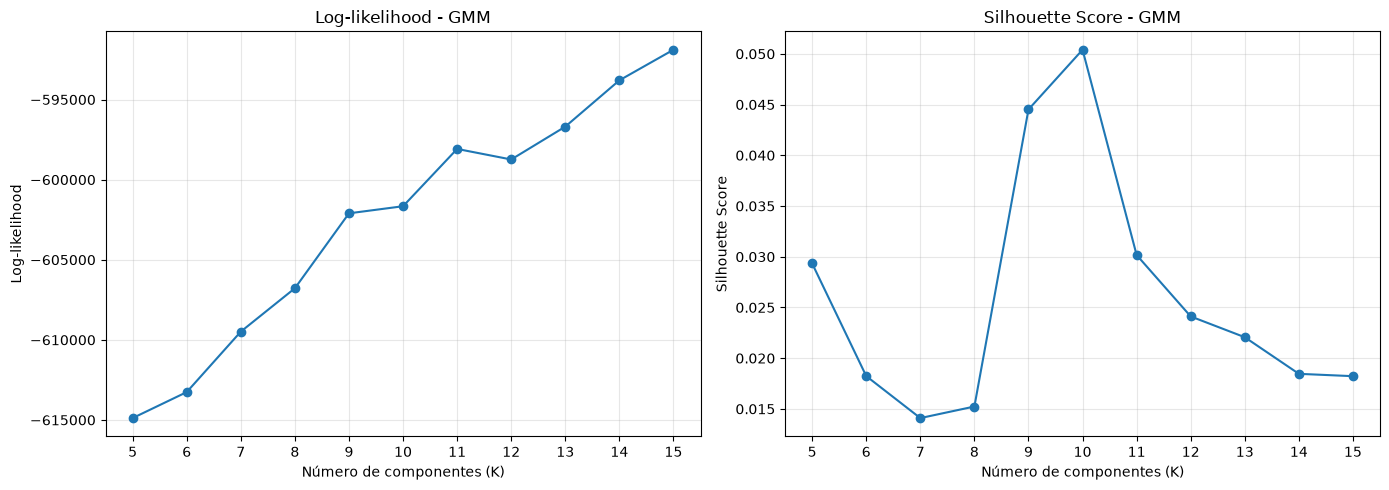

In [106]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Log-likelihood
axes[0].plot(
    list(valores_k_gmm),
    loglik_gmm_k,
    marker="o"
)

axes[0].set_title("Log-likelihood - GMM")
axes[0].set_xlabel("Número de componentes (K)")
axes[0].set_ylabel("Log-likelihood")
axes[0].set_xticks(list(valores_k_gmm))
axes[0].grid(alpha=0.3)

# Silhouette
axes[1].plot(
    list(valores_k_gmm),
    silhouettes_gmm,
    marker="o"
)

axes[1].set_title("Silhouette Score - GMM")
axes[1].set_xlabel("Número de componentes (K)")
axes[1].set_ylabel("Silhouette Score")
axes[1].set_xticks(list(valores_k_gmm))
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

Se evaluaron K-Means y GMM para cantidades de componentes entre 5 y 15, utilizando una muestra estratificada de 3.000 imágenes representadas mediante PCA. K-Means obtuvo su mayor coeficiente Silhouette para K=5, con un valor de 0,1770, mientras que GMM alcanzó su máximo alrededor de K=10, con un valor cercano a 0,050. La log-likelihood del GMM mostró una tendencia creciente al aumentar el número de componentes, aunque con algunas fluctuaciones atribuibles potencialmente a mínimos locales o falta de convergencia. En términos de cohesión y separación euclidiana, K-Means produjo agrupamientos más definidos en este experimento, aunque ambos métodos presentaron valores de Silhouette relativamente bajos.